In [1]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, linestyle_for_language
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()
from utils import makefolder

def load_ii_heatmap(*, base, batch_shuffle, modelA, modelB, aux_A, aux_B, n_files, min_token_length, languageA, languageB, mask, k, Nbits, seeds, n_tokens, avg_tokens, return_std=True):
    mats_ab = []
    mats_ba = []
    for seed in seeds:
        folder = makefolder(
            base=base,
            create_folder=False,
            batch_shuffle=batch_shuffle,
            modelA=modelA,
            modelB=modelB,
            aux_A=aux_A,
            aux_B=aux_B,
            n_files=n_files,
            min_token_length=min_token_length,
            languageA=languageA,
            languageB=languageB,
            mask=mask,
            k=k,
            Nbits=Nbits,
            seed=seed,
        )
        mats_ab.append(np.load(folder + f"n_tokens_{n_tokens}_avg_{avg_tokens}_AB.npy"))
        mats_ba.append(np.load(folder + f"n_tokens_{n_tokens}_avg_{avg_tokens}_BA.npy"))

    stack_ab = np.stack(mats_ab, axis=0)
    stack_ba = np.stack(mats_ba, axis=0)
    mean_ab = stack_ab.mean(axis=0)
    mean_ba = stack_ba.mean(axis=0)

    if return_std:
        ddof = 1 if len(seeds) > 1 else 0
        std_ab = stack_ab.std(axis=0, ddof=ddof)
        std_ba = stack_ba.std(axis=0, ddof=ddof)
        return mean_ab, mean_ba, std_ab, std_ba

    return mean_ab, mean_ba


/home/acevedo/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# Config
# -----------------------
modelA = 'deepseek'
_modelA ='deepseek'

modelB = "llama"
_modelB = 'llama8b'

# modelA = modelB
# _modelA = _modelB

# modelB = modelA
# _modelB = _modelA


mask = 2
language_pairs = [
    # ("english", "spanish"),
    # ("german", "english"),
    # ("english", "italian"),
    # ("english", "hungarian"),
    ("english", "dutch"),
]

n_files = 200
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0

min_token_length = 35
avg_tokens_list = [1]

k_II = 10
Nbits = 0
seeds_II = list(range(5))

n_tokens_list = [20]
n_tokens = n_tokens_list[0]

# Precompute "condition ids" so each (avg_tokens, n_tokens) gets its own color slot
valid_conditions = [
    (avg_tokens, n_tokens)
    for avg_tokens in avg_tokens_list
    for n_tokens in n_tokens_list
    if not (n_tokens == 1 and avg_tokens == 1)
]
cond_to_id = {cond: i for i, cond in enumerate(valid_conditions)}
layersA = get_layers(_modelA, depths)
xA = layersA / depths[_modelA]
layersB = get_layers(_modelB, depths)
xB = layersB / depths[_modelB]

In [7]:
# # -----------------------
# # Heatmaps: modelA vs modelB
# # -----------------------
# for languageA, languageB in language_pairs:
#     aux_A = "source" #if languageA == "english" else "target"
#     aux_B = aux_A
#     for avg_tokens in avg_tokens_list:
#         for n_tokens in n_tokens_list:
#             if n_tokens == 1 and avg_tokens == 1:
#                 continue

#             II_AB, II_BA = load_ii_heatmap(
#                 base="../results/santiago/",
#                 batch_shuffle=batch_shuffle,
#                 modelA=modelA,
#                 modelB=modelB,
#                 aux_A=aux_A,
#                 aux_B=aux_B,
#                 n_files=n_files,
#                 min_token_length=min_token_length,
#                 languageA=languageA,
#                 languageB=languageB,
#                 mask=mask,
#                 k=k_II,
#                 Nbits=Nbits,
#                 seeds=seeds_II,
#                 n_tokens=n_tokens,
#                 avg_tokens=avg_tokens,
#                 return_std=False,
#             )

#             vmin = 0
#             vmax = 1
#             levels = np.linspace(vmin, vmax, 21)

#             fig, ax = plt.subplots(1, 2, figsize=(10, 4))
#             fig.tight_layout()

#             im0 = ax[0].contourf(II_AB, levels=levels, cmap="inferno")
#             im1 = ax[1].contourf(II_BA, levels=levels, cmap="inferno")
#             fig.colorbar(im0, ax=ax, orientation="horizontal", pad=0.15)

#             ax[0].set_title(f"II({modelA} -> {modelB}) | T={n_tokens} | avg={avg_tokens}")
#             ax[1].set_title(f"II({modelB} -> {modelA}) | T={n_tokens} | avg={avg_tokens}")

#             ax[0].set_xlabel(f"layer {modelB}")
#             ax[1].set_xlabel(f"layer {modelB}")
#             ax[0].set_ylabel(f"layer {modelA}")
#             ax[1].set_ylabel(f"layer {modelA}")

#             # Ticks aligned to reduced layer lists (full matrix indices)
#             # Use relative depth axes (xA for modelA, xB for modelB)
#             ax[0].set_xticks(np.arange(II_AB.shape[1]))
#             ax[0].set_xticklabels([f"{v:.2f}" for v in xB])
#             ax[0].set_yticks(np.arange(II_AB.shape[0]))
#             ax[0].set_yticklabels([f"{v:.2f}" for v in xA])

#             ax[1].set_xticks(np.arange(II_BA.shape[1]))
#             ax[1].set_xticklabels([f"{v:.2f}" for v in xB])
#             ax[1].set_yticks(np.arange(II_BA.shape[0]))
#             ax[1].set_yticklabels([f"{v:.2f}" for v in xA])

#             for label in ax[0].get_xticklabels():
#                 label.set_rotation(90)
#             for label in ax[1].get_xticklabels():
#                 label.set_rotation(90)

#             plt.show()

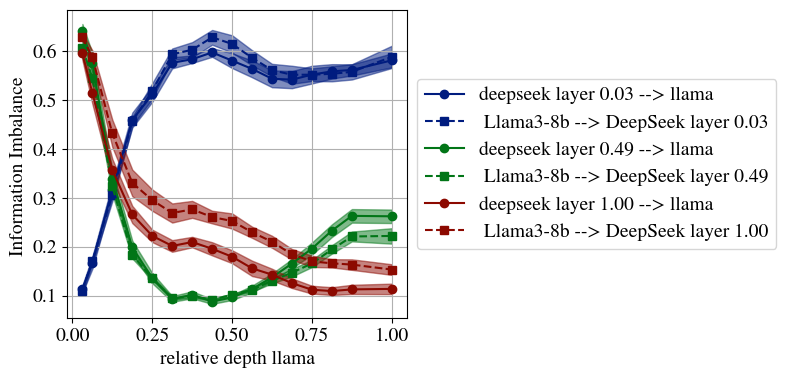

In [8]:
# -----------------------
# 1D slice: pick DS layer with smallest II vs all Llama layers (n_tokens=20)
# -----------------------
# Use first language pair by default

languageA, languageB = language_pairs[0]
aux_A = "target" if languageB == "dutch" else "source"
aux_B = aux_A

# Choose condition for 20 tokens and first avg_tokens value
avg_tokens = avg_tokens_list[0]

II_AB, II_BA, II_AB_std, II_BA_std = load_ii_heatmap(
    base="../results/santiago/",
    batch_shuffle=batch_shuffle,
    modelA=modelA,
    modelB=modelB,
    aux_A=aux_A,
    aux_B=aux_B,
    n_files=n_files,
    min_token_length=min_token_length,
    languageA=languageA,
    languageB=languageB,
    mask=mask,
    k=k_II,
    Nbits=Nbits,
    seeds=seeds_II,
    n_tokens=n_tokens,
    avg_tokens=avg_tokens,
    return_std=True,
)

layer_ids_ds = [
                1, 
                int(len(xA)* 1/2.), 
                # int(len(xA)* 3/5.), 
                # int(len(xA)* 2/5.), 
                len(xA)-1,
                ]

fig, ax = plt.subplots(1, 1, figsize=(7, 4))
for eum_layer_id,layer_id_ds in enumerate(layer_ids_ds):
    ab_mean = II_AB[layer_id_ds, :]
    ab_std = II_AB_std[layer_id_ds, :]
    ba_mean = II_BA[layer_id_ds, :]
    ba_std = II_BA_std[layer_id_ds, :]

    ax.plot(xB, 
            ab_mean, 
            marker='o', 
            linestyle='-', 
            label=f"{modelA} layer {xA[layer_id_ds]:.2f} --> {modelB} ",
            color=colors[eum_layer_id],
            )
    ax.fill_between(xB, ab_mean - ab_std, ab_mean + ab_std,
                    color=colors[eum_layer_id], alpha=0.5)

    ax.plot(xB, 
            ba_mean, 
            marker='s', 
            linestyle='--', 
            label=f" Llama3-8b --> DeepSeek layer {xA[layer_id_ds]:.2f}",
            color=colors[eum_layer_id],
            )
    ax.fill_between(xB, ba_mean - ba_std, ba_mean + ba_std,
                    color=colors[eum_layer_id], alpha=0.50)
    
ax.set_xlabel(f"relative depth {modelB}")
ax.set_ylabel("Information Imbalance ")
# ax.set_title(f'#samples:{Ns} | {len(seeds_II)} seeds')
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.grid()
# ax.legend()
plt.show()

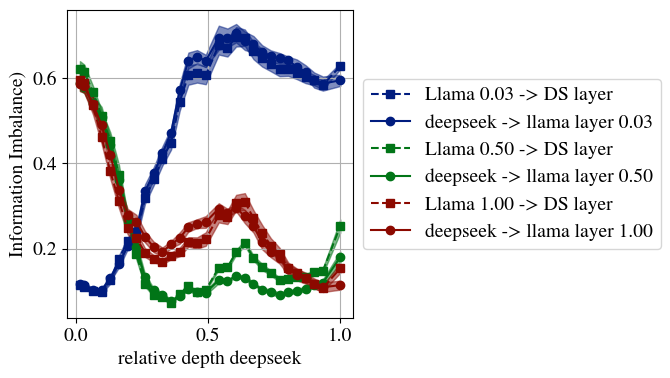

In [9]:
# -----------------------
# 1D slice: Llama -> DeepSeek with reciprocal DS -> Llama
# -----------------------
layer_ids_llama = [
      0,
      len(xB)//2, 
      len(xB)-1,
                   ]

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
for eum_layer_id, layer_id_llama in enumerate(layer_ids_llama):
    ba_mean = II_BA[:, layer_id_llama]
    ba_std = II_BA_std[:, layer_id_llama]
    ab_mean = II_AB[:, layer_id_llama]
    ab_std = II_AB_std[:, layer_id_llama]

    # Llama -> DS (II_BA): sweep DS layers for fixed Llama layer
    ax.plot(
        xA,
        ba_mean,
        marker='s',
        linestyle='--',
        label=f"Llama {xB[layer_id_llama]:.2f} -> DS layer ",
        color=colors[eum_layer_id],
    )
    ax.fill_between(xA, ba_mean - ba_std, ba_mean + ba_std,
                    color=colors[eum_layer_id], alpha=0.5)

    # DS -> Llama (II_AB): sweep DS layers for the same fixed Llama layer
    ax.plot(
        xA,
        ab_mean,
        marker='o',
        linestyle='-',
        color=colors[eum_layer_id],
        label=f"{modelA} -> {modelB} layer {xB[layer_id_llama]:.2f}",
    )
    ax.fill_between(xA, ab_mean - ab_std, ab_mean + ab_std,
                    color=colors[eum_layer_id], alpha=0.5)

ax.set_xlabel(f"relative depth {modelA}")
ax.set_ylabel("Information Imbalance)")
# ax.set_title(f'#samples:{Ns} | {len(seeds_II)} seeds')
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.grid()

# ax.legend()
plt.show()